In [25]:
'''
This file calculates the pearson correlation between the top N features
'''
import pickle
import pandas as pd
import seaborn as sb
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

In [26]:
def load_data(fold_num):
    return pd.read_csv(f"bcg_dataset/feat_fold_{fold_num}.csv")

def load_all_data():
    """
    Load and combine all pre-split folds into one dataset
    
    The original dataset comes pre-split into 5 folds, but I combine them so I can split using
    groups over the patient id
    """
    all_folds = []
    for fold_num in range(5):
        fold_data = load_data(fold_num)
        all_folds.append(fold_data)
    
    combined = pd.concat(all_folds, ignore_index=True)
    print(f"Combined dataset shape: {combined.shape}")
    print(f"Total samples: {len(combined)}")
    
    return combined

In [ ]:
def remove_highly_correlated_features(top_features, data):
    feature_names = [f for f,_ in top_features]
    importances   = {f: imp for f, imp in top_features}
    X = data[feature_names]

    # Find the correlated pairs
    correlated_pairs = []
    for i in range(len(feature_names)):
        for j in range(i+1, len(feature_names)):
            f1, f2 = feature_names[i], feature_names[j]
            r, p = pearsonr(X[f1], X[f2])
            # check if this is 'and' or 'or'?
            if abs(r) >= 0.85 and p < 0.05:
                correlated_pairs.append((f1, f2, r, p))

    # remove the correlated feature of lower importance
    toDrop = set()
    for f1, f2, r, p in correlated_pairs:
        if f1 not in toDrop and f2 not in toDrop:
            drop = f2 if importances[f1] >= importances[f2] else f1
            toDrop.add(drop)

    filtered = [(f,imp) for f,imp in top_features if f not in toDrop]   # kept features
    
    return filtered, correlated_pairs, toDrop

AUCsys_norm
Top SBP 33 features with a cumulative importance of 0.6653955357321185
  1 AUCsys_norm                              0.125667
  2 TdiaToEnd                                0.116956
  3 AUCdia_norm                              0.062830
  4 T_peak_e_norm                            0.050434
  5 ppg_histogram_down_2                     0.026807
  6 T_peak_a                                 0.025653
  7 SteepDiaRise                             0.021742
  8 TNegSteepest_norm                        0.019118
  9 vpg_max_neighbor_mean_0                  0.017178
 10 ppg4_max_0                               0.015860
 11 TSystoDiaRise                            0.014518
 12 ppg3_histogram_down_8                    0.013950
 13 usdc_2                                   0.011176
 14 T_peak_e                                 0.009860
 15 vpg_histogram_down_0                     0.009217
 16 apg_histogram_down_3                     0.008568
 17 TNegSteepest                             0.008305

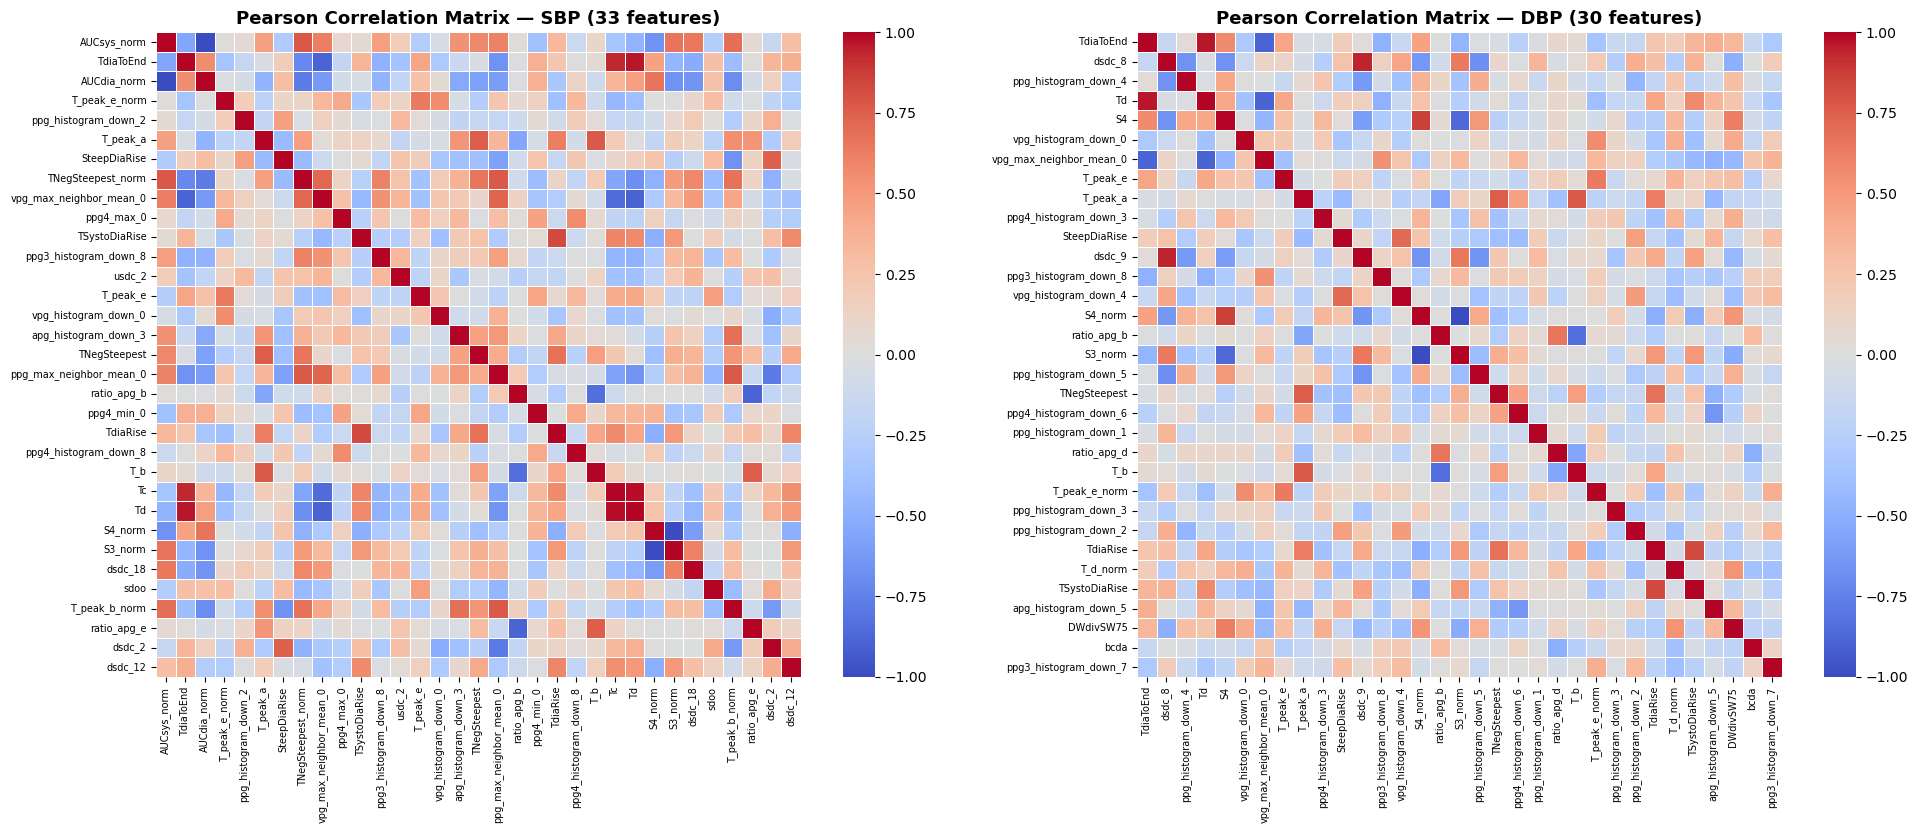

For SBP: 
Filtered Features [('AUCsys_norm', np.float64(0.1256669297834789)), ('TdiaToEnd', np.float64(0.11695573402302499)), ('T_peak_e_norm', np.float64(0.0504343398390225)), ('ppg_histogram_down_2', np.float64(0.026807303428338546)), ('T_peak_a', np.float64(0.02565264654979771)), ('SteepDiaRise', np.float64(0.02174193211756468)), ('TNegSteepest_norm', np.float64(0.019117636913318803)), ('ppg4_max_0', np.float64(0.015859775021095073)), ('TSystoDiaRise', np.float64(0.014517775886147888)), ('ppg3_histogram_down_8', np.float64(0.013950211151381665)), ('usdc_2', np.float64(0.011175795363846164)), ('T_peak_e', np.float64(0.009860046967519583)), ('vpg_histogram_down_0', np.float64(0.009216814524496297)), ('apg_histogram_down_3', np.float64(0.008567743510567872)), ('TNegSteepest', np.float64(0.008304747870410363)), ('ppg_max_neighbor_mean_0', np.float64(0.008007726789517259)), ('ratio_apg_b', np.float64(0.007991957146365702)), ('ppg4_min_0', np.float64(0.007671464101782388)), ('TdiaRise', n

In [ ]:
with open("results_RF_importances/rf_results.pkl", "rb") as file:
    results = pickle.load(file)

SBP_features = [(f,imp) for (f, imp) in results["sbp_ranking"][:218]]
DBP_features = [(f,imp) for (f, imp) in results["dbp_ranking"][:218]]
print(SBP_features[0][0])

# Get the top features to get over 2/3 of total feature importance
sumImpSBP = 0
sumImpDBP = 0
num_features_SBP = 0
num_features_DBP = 0

for i in range (len(SBP_features)):
    sumImpSBP += SBP_features[i][1]
    num_features_SBP += 1
    if sumImpSBP>=0.66:
        break

for i in range (len(DBP_features)):
    sumImpDBP += DBP_features[i][1]
    num_features_DBP += 1
    if sumImpDBP>=0.66:
        break

print(f"Top SBP {num_features_SBP} features with a cumulative importance of {sumImpSBP}")
for i, (f, imp) in enumerate(SBP_features[:num_features_SBP], 1):
    print(f"{i:>3} {f:<40} {imp:.6f}")

print(f"\n\nTop SBP {num_features_DBP} features with a cumulative importance of {sumImpDBP}")
for i, (f, imp) in enumerate(DBP_features[:num_features_DBP], 1):
    print(f"{i:>3} {f:<40} {imp:.6f}")

top_N_features = num_features_SBP if num_features_SBP >= num_features_DBP else num_features_DBP

# Keep tuples with importance
top_features_SBP = results["sbp_ranking"][:top_N_features]
top_features_DBP = results["dbp_ranking"][:top_N_features]

# Only feature names
top_feature_names_SBP = [f for f, _ in top_features_SBP]
top_feature_names_DBP = [f for f, _ in top_features_DBP]

data = load_all_data()

X_SBP = data[top_feature_names_SBP]
X_DBP = data[top_feature_names_DBP]

corr_SBP = X_SBP.corr(method="pearson")
corr_DBP = X_DBP.corr(method="pearson")

# Plot
fig, axes = plt.subplots(1, 2, figsize=(20, 8))

sb.heatmap(
    corr_SBP,
    ax=axes[0],
    cmap='coolwarm',
    center=0,
    vmin=-1, vmax=1,
    square=True,
    linewidths=0.5,
    annot=False,          # Set True if num_features_SBP is small enough
    xticklabels=True,
    yticklabels=True
)
axes[0].set_title(f'Pearson Correlation Matrix — SBP ({num_features_SBP} features)', fontsize=13, fontweight='bold')
axes[0].tick_params(axis='x', rotation=90, labelsize=7)
axes[0].tick_params(axis='y', rotation=0,  labelsize=7)

sb.heatmap(
    corr_DBP,
    ax=axes[1],
    cmap='coolwarm',
    center=0,
    vmin=-1, vmax=1,
    square=True,
    linewidths=0.5,
    annot=False,
    xticklabels=True,
    yticklabels=True
)
axes[1].set_title(f'Pearson Correlation Matrix — DBP ({num_features_DBP} features)', fontsize=13, fontweight='bold')
axes[1].tick_params(axis='x', rotation=90, labelsize=7)
axes[1].tick_params(axis='y', rotation=0,  labelsize=7)

plt.tight_layout()
plt.savefig('results_RF_importances/pearson_correlation_matrix.png', dpi=300, bbox_inches='tight')
plt.show()

# I define high correlation, if absolute(r) ≥ 0.85 and p < 0.05
filtered_SBP, pairs_SBP, dropped_SBP = remove_highly_correlated_features(top_features_SBP, data)
print(f"For SBP: \nFiltered Features {filtered_SBP} \nHighly correlated values {pairs_SBP} \nDropped features {dropped_SBP}\n\n")

filtered_DBP, pairs_DBP, dropped_DBP = remove_highly_correlated_features(top_features_DBP, data)
print(f"For DBP: \nFiltered Features {filtered_DBP} \nHighly correlated values {pairs_DBP} \nDropped features {dropped_DBP}")

'''
filtered_names_sbp = [f for f,_ in filtered_SBP]
filtered_names_dbp = [f for f,_ in filtered_DBP]
filtered_importances_sbp = [imp for _,imp in filtered_SBP]
filtered_importances_dbp = [imp for _,imp in filtered_DBP]
'''

with open("results_RF_importances/rf_results.pkl", "rb") as f:
    file = pickle.load(f)

file.update({
    "sbp_ranking_pearson": filtered_SBP,
    "dbp_ranking_pearson": filtered_DBP
})
print([f for f,_ in filtered_SBP])
print([f for f,_ in filtered_DBP])

with open("results_RF_importances/rf_results.pkl", "wb") as f:
    pickle.dump(file, f)
